#  Concept Exercise: Multi-Feature Tech Salary Prediction (Starter Notebook)

Welcome to the guided exercise for **Submodule 01: Linear & Multiple Regression**!

---
###  Objectives:
1. Load and explore a synthetic Tech Salary dataset containing continuous predictors.
2. Prepare feature matrices ($X$) and target vectors ($y$), including train-test splitting.
3. Fit a Scikit-Learn `LinearRegression` model on the training set.
4. Calculate and interpret regression evaluation metrics (**MAE**, **MSE**, **RMSE**, **$R^2$**, **Adjusted $R^2$**).
5. Extract and analyze model coefficients ($\beta_j$).

---
###  Instructions:
* Follow the step-by-step TODO prompts below.
* Complete the missing code sections marked with `# TODO: ...`.

## Task 1: Environment Setup & Dataset Generation

Execute the cell below to set up your environment and generate the synthetic software engineer dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# Set global plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Seed for reproducibility
np.random.seed(42)
n_samples = 200

# Synthetic Tech Salary Dataset Generation
years_experience = np.random.uniform(1, 15, size=n_samples)
certifications = np.random.poisson(lam=2, size=n_samples)
performance_rating = np.random.uniform(3.0, 5.0, size=n_samples)
hours_per_week = np.random.normal(40, 4, size=n_samples)

# Underlying true data generating function
salary = (
    45000
    + 9500 * years_experience
    + 3500 * certifications
    + 12000 * performance_rating
    + 200 * hours_per_week
    + np.random.normal(0, 6000, size=n_samples)
)

df_salary = pd.DataFrame({
    "years_experience": years_experience.round(1),
    "certifications": certifications,
    "performance_rating": performance_rating.round(2),
    "hours_per_week": hours_per_week.round(1),
    "salary": salary.round(2)
})

print("--- Tech Salary Dataset Preview ---")
print(df_salary.head())

--- Tech Salary Dataset Preview ---
   years_experience  certifications  performance_rating  hours_per_week  \
0               6.2               1                4.28            33.2   
1              14.3               2                4.39            43.9   
2              11.2               0                4.09            38.6   
3               9.4               0                3.50            41.0   
4               3.2               1                3.69            40.7   

      salary  
0  173344.94  
1  252337.89  
2  202414.54  
3  184060.17  
4  133440.93  


---
## Task 2: Feature Matrix & Target Splitting

1. Define feature matrix `X` containing all columns except `salary`.
2. Define target vector `y` containing the `salary` column.
3. Split the data into **80% training** and **20% testing** sets using `train_test_split(random_state=42)`.

In [2]:
# Define X and y
X = df_salary.drop(columns=["salary"])
y = df_salary["salary"]

# Perform 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape : {X_test.shape}")


Training set shape: (160, 4)
Testing set shape : (40, 4)


---
## Task 3: Fit Linear Regression Model

Instantiate Scikit-Learn's `LinearRegression` model and fit it **strictly on the training data** (`X_train`, `y_train`).

In [3]:
# Instantiate and fit LinearRegression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training complete!")


Model training complete!


---
## Task 4: Model Evaluation & Metrics Calculation

1. Predict test set targets `y_pred` using `X_test`.
2. Compute **MAE**, **MSE**, **RMSE**, and **$R^2$** on the test set using `scikit-learn` metrics.
3. Implement the formula for **Adjusted $R^2$**:
   $$R^2_{\text{adj}} = 1 - \left[ \frac{(1 - R^2)(n - 1)}{n - p - 1} \right]$$

In [4]:
# Generate test set predictions
y_pred = model.predict(X_test)

# Calculate standard metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Compute Adjusted R²
n = len(y_test)
p = X_train.shape[1]
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("--- Evaluation Metrics (Test Set) ---")
print(f"MAE        : ₹{mae:,.2f}")
print(f"MSE        : ₹{mse:,.2f}")
print(f"RMSE       : ₹{rmse:,.2f}")
print(f"R² Score   : {r2:.4f}")
print(f"Adjusted R²: {adj_r2:.4f}")


--- Evaluation Metrics (Test Set) ---
MAE        : ₹4,768.02
MSE        : ₹33,633,761.01
RMSE       : ₹5,799.46
R² Score   : 0.9779
Adjusted R²: 0.9754


---
## Task 5: Coefficient Analysis & Visualization

1. Extract `model.intercept_` and `model.coef_`.
2. Create a summary DataFrame showing each feature and its learned coefficient.
3. Plot Actual vs. Predicted values for the test set.

Learned Intercept (Beta 0): ₹34998.43

--- Learned Feature Weights ---
           Feature  Coefficient (₹)
performance_rating     14336.273247
  years_experience      9604.762882
    certifications      3296.112016
    hours_per_week       217.795759


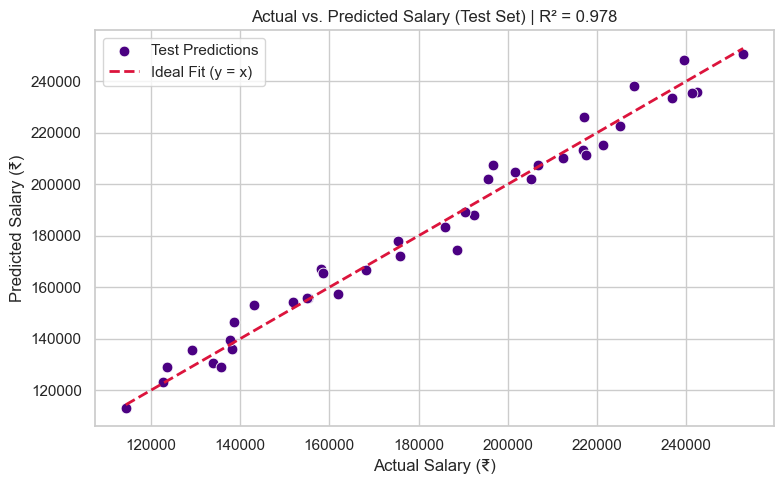

In [5]:
# Print intercept
print(f"Learned Intercept (Beta 0): ₹{model.intercept_:.2f}")

# Create coefficient DataFrame
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient (₹)": model.coef_
}).sort_values(by="Coefficient (₹)", ascending=False)
print("\n--- Learned Feature Weights ---")
print(coef_df.to_string(index=False))

# Plot Actual vs Predicted Salary Scatter plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_test, y=y_pred, color="indigo", s=60, label="Test Predictions")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="crimson", linestyle="--", linewidth=2, label="Ideal Fit (y = x)")
plt.title(f"Actual vs. Predicted Salary (Test Set) | R² = {r2:.3f}")
plt.xlabel("Actual Salary (₹)")
plt.ylabel("Predicted Salary (₹)")
plt.legend()
plt.tight_layout()
plt.show()
